# Devoir 1 — Analyse des données de stress et de symptômes

**Cours : 201-C72 — Mathématiques pour l'IA**  
**Source :** `Devoir-Data-c72.xlsx`  
**Étudiant(s) :** à compléter

Ce notebook présente les calculs en Python et les explications statistiques. Les données contiennent 95 étudiants et deux variables : `Stress` et `Symptomes`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.precision', 4)

fichier = 'Devoir-Data-c72.xlsx'
df = pd.read_excel(fichier)
df.columns = ['Stress', 'Symptomes']
df = df.dropna().copy()
n = len(df)
df.head()

,Stress,Symptomes
0,30,4.5951
1,27,4.5433
2,9,4.3820
3,20,4.2485
4,3,4.6052


## 1. Mesures descriptives

On utilise les données non groupées, comme demandé. La moyenne et la médiane mesurent la tendance centrale. L'étendue et l'écart-type mesurent la dispersion. Le coefficient de variation compare la dispersion à la moyenne :

$$CV=\frac{s}{\bar{x}}\times100\%.$$

Les quartiles $Q_1$ et $Q_3$ indiquent les positions sous lesquelles se trouvent respectivement 25 % et 75 % des observations. L'écart-type calculé par `pandas` utilise $n-1$, ce qui correspond à l'écart-type d'un échantillon.

**Formules utilisées :**

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i,\qquad
s=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}.$$

$$\text{Étendue}=x_{\max}-x_{\min},\qquad
CV=\frac{s}{\bar{x}}\times100\%.$$

Les quartiles sont calculés sur les données non groupées : $Q_1$ est le 25e percentile et $Q_3$ le 75e percentile.

Le code utilise `mean()`, `median()`, `std(ddof=1)`, `quantile()` et `max()-min()` pour appliquer ces formules aux observations individuelles.



In [8]:
lignes = []
for variable in ['Stress', 'Symptomes']:
    x = df[variable]
    
    lignes.append({
        'Variable': variable,
        'Moyenne': x.mean(),
        'Médiane': x.median(),
        'Étendue': x.max() - x.min(),
        'Écart-type s': x.std(ddof=1),# ddof=1 utilise n-1 au dénominateur, comme pour l'écart-type d'un échantillon.
        'CV (%)': 100 * x.std(ddof=1) / x.mean(),
        'Q1': x.quantile(0.25),
        'Q3': x.quantile(0.75)
    })
tableau_descriptif = pd.DataFrame(lignes).set_index('Variable')
tableau_descriptif

,Moyenne,Médiane,Étendue,Écart-type s,CV (%),Q1,Q3
Variable,,,,,,,
Stress,20.6947,20.0000,44.0000,11.4121,55.1449,12.5000,29.0000
Symptomes,4.4818,4.4773,1.1653,0.2115,4.7199,4.3503,4.6052


**Application aux données :**

- Stress : $\bar{x}=20{,}6947$, $s=11{,}4121$, étendue $=45-1=44$, $CV=55{,}14\%$, $Q_1=12{,}5$, $Q_3=29$.
- Symptômes : $\bar{y}=4{,}4818$, $s_y=0{,}2115$, étendue $=5{,}2257-4{,}0604=1{,}1653$, $CV=4{,}72\%$, $Q_1=4{,}3503$, $Q_3=4{,}6052$.

 **Interprétation :** 
 
Le stress varie fortement d’un étudiant à l’autre : son écart-type est de 11,412 et son coefficient de variation est d’environ 55,14%. Les niveaux de stress sont donc très hétérogènes dans cet échantillon, ce qui peut justifier une attention particulière aux besoins individuels en matière de prévention et de soutien.

Le score de symptômes est beaucoup plus homogène : son écart-type est de 0,212 et son coefficient de variation est d’environ 4,72,%. Les scores sont concentrés autour de 4,482, ce qui indique des niveaux de symptômes relativement similaires chez les étudiants de cet échantillon.

La moyenne et la médiane des symptômes sont presque identiques 4,482 contre 4,477. La distribution semble donc peu asymétrique, et la moyenne représente assez bien le groupe. Toutefois, cette faible dispersion peut limiter la capacité à distinguer les étudiants selon leur niveau de symptômes. Enfin, il faut éviter de conclure que le stress cause les symptômes : ces statistiques décrivent les données, mais ne permettent pas d’établir une relation causale.

## 2. Tableaux de fréquences et histogrammes

La règle de Sturges donne environ $1+\log_2(95)\approx7{,}57$, donc 8 classes est un choix raisonnable pour décrire les distributions. Les classes ont la même amplitude dans chaque variable. Les bornes sont calculées séparément, car les unités et les étendues de `Stress` et `Symptomes` sont différentes.


**Formules utilisées :**

$$
h=\frac{x_{\max}-x_{\min}}{k},
$$

où $k=8$ est le nombre de classes choisi avec la règle de Sturges :

$$
k\approx 1+\log_2(n)
=1+\log_2(95)
\approx 7{,}57
\approx 8.
$$

Pour chaque classe :

$$
f_i=\frac{n_i}{n}\times100\%,
$$

ou $n_i$ est l'effectif de la classe et $f_i$ sa fréquence relative. Les bornes sont calcul?es avec `np.linspace()` afin d'obtenir des classes de même amplitude. L'histogramme represente les effectifs par classe.

**Solution :** les fréquences sont calculées séparement pour Stress et Symptomes, car les deux variables n'ont pas la même unité ni la même étendue. Les tableaux et les deux histogrammes produits par la cellule suivante constituent la réponse à la question 2.



Tableau de fréquences et Stress


,Effectif,Fréquence (%)
Stress,,
"(0.999, 6.5]",9,9.4737
"(6.5, 12.0]",15,15.7895
"(12.0, 17.5]",20,21.0526
"(17.5, 23.0]",18,18.9474
"(23.0, 28.5]",8,8.4211
"(28.5, 34.0]",12,12.6316
"(34.0, 39.5]",8,8.4211
"(39.5, 45.0]",5,5.2632


Tableau de fréquences et Symptomes


,Effectif,Fréquence (%)
Symptomes,,
"(4.058999999999999, 4.206]",10,10.5263
"(4.206, 4.352]",14,14.7368
"(4.352, 4.497]",28,29.4737
"(4.497, 4.643]",26,27.3684
"(4.643, 4.789]",9,9.4737
"(4.789, 4.934]",6,6.3158
"(4.934, 5.08]",1,1.0526
"(5.08, 5.226]",1,1.0526


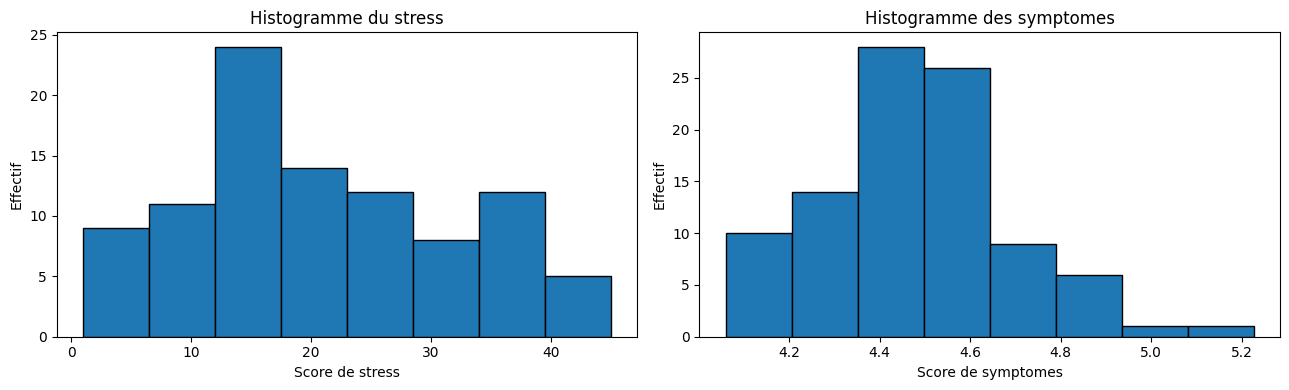

In [9]:
def tableau_frequences(x, nombre_classes=8):
    # Crée les bornes des classes avec des intervalles de même amplitude.
    # Il y aura nombre_classes + 1 bornes pour former nombre_classes intervalles.
    bornes = np.linspace(x.min(), x.max(), nombre_classes + 1)

    # Associe chaque observation à une classe selon les bornes calculées.
    # include_lowest=True inclut la plus petite valeur dans la première classe.
    classes = pd.cut(x, bins=bornes, include_lowest=True)

    # Compte le nombre d'observations dans chaque classe.
    # sort=False conserve l'ordre naturel des classes.
    effectifs = classes.value_counts(sort=False)

    # Crée un DataFrame contenant les effectifs par classe.
    resultat = pd.DataFrame({'Effectif': effectifs})

    # Calcule la fréquence de chaque classe en pourcentage.
    # len(x) représente le nombre total d'observations.
    resultat['Fréquence (%)'] = 100 * resultat['Effectif'] / len(x)

    # Retourne les bornes et le tableau de fréquences.
    return bornes, resultat

bornes_stress, freq_stress = tableau_frequences(df['Stress'])
bornes_symptomes, freq_symptomes = tableau_frequences(df['Symptomes'])
print('Tableau de fréquences et Stress')
display(freq_stress)
print('Tableau de fréquences et Symptomes')
display(freq_symptomes)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['Stress'], bins=bornes_stress, edgecolor='black')
axes[0].set(title='Histogramme du stress', xlabel='Score de stress', ylabel='Effectif')
axes[1].hist(df['Symptomes'], bins=bornes_symptomes, edgecolor='black')
axes[1].set(title='Histogramme des symptomes', xlabel='Score de symptomes', ylabel='Effectif')
plt.tight_layout()
plt.show()


## 3. Proportions autour de la moyenne

Pour la variable $Y=$ `Symptomes`, on calcule les proportions observées dans :

$$[\bar y-s_y,\bar y+s_y],$$
$$[\bar y-1{,}96s_y,\bar y+1{,}96s_y],$$
$$[\bar y-2{,}575s_y,\bar y+2{,}575s_y].$$

Pour une loi normale, les proportions théoriques correspondantes sont environ 68,27 %, 95,00 % et 98,997 %.


On obtient ces valeurs à partir des observations de la colonne `Symptomes` :

$$
\bar{y}=\frac{1}{n}\sum_{i=1}^{n}y_i
=4{,}4818
$$

et l'écart-type de l'échantillon est calculé par :

$$
s_y=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(y_i-\bar{y})^2}
=0{,}2115.
$$

Ces valeurs sont calculées dans le tableau descriptif avec `mean()` et `std(ddof=1)`. On pose donc $Y=$ score de symptômes, avec une moyenne $\bar{y}=4{,}4818$ et un écart-type $s_y=0{,}2115$. Pour chaque valeur $z$, on compte les observations vérifiant :

$$
\bar{y}-zs_y\le Y\le\bar{y}+zs_y.
$$

La proportion observée est :

$$
\widehat{P}=
\frac{\text{nombre d'observations dans l'intervalle}}{n}.
$$

Pour une loi normale standard :

$$
P(-z\le Z\le z)=\Phi(z)-\Phi(-z).
$$

**Résultats :**

| Intervalle | Proportion observée | Proportion normale théorique |
|---|---:|---:|
| $\bar{y}\pm s_y$ | $68/95=71{,}58\%$ | $68{,}27\%$ |
| $\bar{y}\pm1{,}96s_y$ | $90/95=94{,}74\%$ | $95{,}00\%$ |
| $\bar{y}\pm2{,}575s_y$ | $94/95=98{,}95\%$ | $99{,}00\%$ |

Le code applique directement ces bornes et utilise `stats.norm.cdf()` pour calculer les proportions théoriques.



In [10]:
y = df['Symptomes']
moyenne_y = y.mean()
ecart_type_y = y.std(ddof=1)
facteurs = [1, 1.96, 2.575]
lignes = []
for facteur in facteurs:
    bas = moyenne_y - facteur * ecart_type_y
    haut = moyenne_y + facteur * ecart_type_y
    nombre = ((y >= bas) & (y <= haut)).sum()
    proportion = nombre / n
    theorique = stats.norm.cdf(facteur) - stats.norm.cdf(-facteur)
    lignes.append({'Facteur': facteur, 'Borne inférieure': bas,
                   'Borne supérieure': haut, 'Nombre': nombre,
                   'Proportion observée (%)': 100 * proportion,
                   'Proportion normale (%)': 100 * theorique})
pd.DataFrame(lignes)


,Facteur,Borne inférieure,Borne supérieure,Nombre,Proportion observée (%),Proportion normale (%)
0,1.000,4.2703,4.6933,68,71.5789,68.2689
1,1.960,4.0672,4.8964,90,94.7368,95.0004
2,2.575,3.9371,5.0265,94,98.9474,98.9976


**Interprétation.** Les proportions observées sont environ 71,58 %, 94,74 % et 98,95 %. Elles sont proches des valeurs normales 68,27 %, 95,00 % et 98,997 %, particulièrement pour les intervalles de 1,96 et 2,575 écarts-types. Ce résultat est compatible avec une distribution approximativement normale, mais il ne constitue pas à lui seul une preuve.

## 4. Le score de symptômes semble-t-il normal ?

>On peut raisonnablement supposer une normalité approximative pour trois raisons :

**Arguments utilisés :**

1. **Moyenne et médiane :** sont très proches : $4{,}4818$ contre $4{,}4773$, ce qui indique une asymétrie limitée.
2. **Comparaison empirique :** Les proportions observées dans les intervalles $\bar y\pm s_y$, $\bar y\pm1{,}96s_y$ et $\bar y\pm2{,}575s_y$ sont proches des proportions normales $68{,}27\%$, $95\%$ et $99\%$.
3. **Histogramme :** présente une concentration principalement entre $4{,}35$ et $4{,}64$, sans asymétrie extrême. Le QQ-plot permet également de vérifier si les quantiles observés suivent approximativement une droite.

**Conclusion :** on peut supposer une normalité approximative du score de symptômes. Toutefois, aucune vérification graphique ou numérique ne prouve à elle seule une normalité parfaite. Cette démarche reprend le Labo 3 sur le QQ-plot.



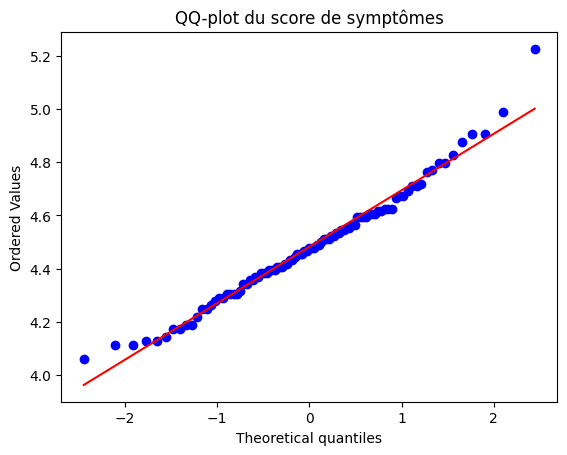

In [11]:
stats.probplot(y, dist='norm', plot=plt)
plt.title('QQ-plot du score de symptômes')
plt.show()


**Interprétation :**

 Les points du QQ-plot suivent globalement la droite de référence, avec de légers écarts aux extrémités. Le score de symptômes peut donc être considéré comme approximativement normal, sans que cela prouve une normalité parfaite.



## 5. Intervalle de confiance à 95 % pour la moyenne

L'écart-type de la population n'est pas connu. On utilise donc la loi de Student avec $n-1=94$ degrés de liberté :

$$\bar y\pm t_{0{,}025;94}\frac{s_y}{\sqrt n}.$$

L'erreur standard est $SE=s_y/\sqrt n$ et la marge d'erreur est $ME=t^*SE$.


Comme l'écart-type de la population est inconnu, on utilise la loi de Student :

$$
IC_{95\%}=
\left[
\bar y-t_{0{,}025;n-1}\frac{s_y}{\sqrt n},
\quad
\bar y+t_{0{,}025;n-1}\frac{s_y}{\sqrt n}
\right].
$$



In [12]:
ddl = n - 1
alpha = 0.05
t_critique = stats.t.ppf(1 - alpha/2, ddl)
se_y = ecart_type_y / np.sqrt(n)
marge = t_critique * se_y
ci = (moyenne_y - marge, moyenne_y + marge)
print(f'n = {n}, degrés de liberté = {ddl}')
print(f'moyenne = {moyenne_y:.6f}, s = {ecart_type_y:.6f}')
print(f'erreur standard = {se_y:.6f}')
print(f't critique = {t_critique:.6f}')
print(f"marge d'erreur = {marge:.6f}")
print(f'IC de 95 % = [{ci[0]:.6f}, {ci[1]:.6f}]')


n = 95, degrés de liberté = 94
moyenne = 4.481809, s = 0.211537
erreur standard = 0.021703
t critique = 1.985523
marge d'erreur = 0.043092
IC de 95 % = [4.438717, 4.524901]


**Étapes numériques :**

$$n=95,\qquad ddl=n-1=94,$$

$$
SE=\frac{s_y}{\sqrt n}
=\frac{0{,}2115}{\sqrt{95}}
\approx0{,}02170,
$$

$$t_{0{,}025;94}\approx1{,}9855,$$

$$
ME=t^*SE
\approx1{,}9855(0{,}02170)
=0{,}04309.
$$

Donc :

$$
IC_{95\%}=4{,}4818\pm0{,}0431
=[4{,}4387;4{,}5249].
$$


**Interprétation détaillée.**

L'intervalle de confiance à 95 % pour la moyenne de la population est :

$$
IC_{95\%}=[4{,}4387\,;\,4{,}5249].
$$

La moyenne observée dans l'échantillon de 95 étudiants est de $4{,}4818$. La marge d'erreur est d'environ $0{,}0431$, ce qui signifie que l'intervalle est construit autour de la moyenne :

$$
4{,}4818\pm0{,}0431.
$$

Ainsi, selon cette méthode, la moyenne réelle du score de symptômes dans la population étudiée est estimée entre $4{,}4387$ et $4{,}5249$ avec un niveau de confiance de 95 %. L'intervalle est relativement étroit, ce qui indique une estimation assez précise de la moyenne.

Cette précision s'explique notamment par la taille de l'échantillon ($n=95$) et par la faible variabilité des scores de symptômes ($s_y\approx0{,}2115$). La moyenne hypothétique de $4{,}5$ appartient à l'intervalle, ce qui est cohérent avec le test d'hypothèse précédent : les données ne permettent pas d'affirmer que la moyenne de la population est inférieure à $4{,}5$.

Il faut toutefois interpréter le niveau de confiance correctement : si l'on répétait plusieurs fois l'échantillonnage et la construction de l'intervalle avec la même méthode, environ 95 % des intervalles ainsi obtenus contiendraient la véritable moyenne de la population. On ne dit donc pas que la probabilité que la moyenne soit dans cet intervalle est de 95 %, puisque la moyenne réelle est une valeur fixe.

Enfin, cette conclusion suppose que l'échantillon est suffisamment représentatif de la population des étudiants étudiée. L'intervalle décrit l'incertitude liée à l'estimation de la moyenne, mais ne permet pas de généraliser les résultats à une population différente sans justification.

## 6. Taille d'échantillon pour une marge d'erreur de 0,025

Pour une estimation de moyenne à 95 %, on utilise l'approximation normale et l'écart-type pilote $s_y$ :

$$
n=\left(\frac{z_{0{,}025}s_y}{ME}\right)^2.
$$

Il faut toujours arrondir vers le haut, car une taille plus petite pourrait dépasser la marge d'erreur demandée.

Pour une moyenne, la marge d'erreur approximative à 95 % est :

$$
ME=z_{0{,}025}\frac{s_y}{\sqrt n}.
$$

On impose $ME\le0{,}025$ et on isole $n$ :

$$
n\ge\left(\frac{z_{0{,}025}s_y}{ME}\right)^2.
$$

Avec $z_{0{,}025}=1{,}96$ et $s_y=0{,}2115$ :

$$
n\ge\left(\frac{1{,}96(0{,}2115)}{0{,}025}\right)^2
\approx274{,}64.
$$

Une taille d'échantillon doit être entière et arrondie vers le haut :

$$
\boxed{n=275}.
$$

L'écart-type de l'échantillon est utilisé ici comme estimation pilote de l'écart-type de la population.



In [13]:
me_souhaitee = 0.025
z_critique = stats.norm.ppf(0.975)
n_reel = (z_critique * ecart_type_y / me_souhaitee) ** 2
n_choisi = int(np.ceil(n_reel))
print(f'n théorique = {n_reel:.6f}')
print(f'taille minimale entière = {n_choisi}')


n théorique = 275.035209
taille minimale entière = 276


**Réponse.** Il faut choisir au moins **276 étudiants** selon cette approximation. Le calcul utilise l'écart-type observé comme estimation de l'écart-type de la population; si une valeur de population connue était fournie, elle remplacerait $s_y$.

## 7. Test de l'hypothèse $\mu<4{,}5$

On veut déterminer si la moyenne de la population est inférieure à 4,5. Le test est unilatéral à gauche :

$$H_0:\mu=4{,}5\quad\text{(ou }\mu\ge4{,}5\text{)},$$
$$H_1:\mu<4{,}5.$$

Comme $\sigma$ est inconnue, la statistique de test est :

$$t=\frac{\bar y-\mu_0}{s_y/\sqrt n}.$$

Au seuil de 5 %, on rejette $H_0$ si $t<t_{0{,}05;94}$.


On veut vérifier si $\mu<4{,}5$. On pose donc :

$$H_0:\mu\ge4{,}5\quad\text{(calcul effectué avec }\mu_0=4{,}5\text{)},$$
$$H_1:\mu<4{,}5.$$

Comme $\sigma$ est inconnue, la statistique de Student est :

$$t=\frac{\bar y-\mu_0}{s_y/\sqrt n}.$$

**Calcul :**

$$t=\frac{4{,}4818-4{,}5}{0{,}2115/\sqrt{95}}\approx-0{,}8382.$$

Au seuil $\alpha=0{,}05$ et avec 94 degrés de liberté, la valeur critique est :

$$t_{0{,}05;94}\approx-1{,}6612.$$

La valeur-p est d'environ $0{,}2020$. Comme $-0{,}8382>-1{,}6612$ et que $0{,}2020>0{,}05$, on ne rejette pas $H_0$.




In [14]:
mu0 = 4.5
t_obs = (moyenne_y - mu0) / se_y
p_value = stats.t.cdf(t_obs, ddl)
t_crit_gauche = stats.t.ppf(0.05, ddl)
print(f't observé = {t_obs:.6f}')
print(f'valeur critique à gauche = {t_crit_gauche:.6f}')
print(f'valeur-p = {p_value:.6f}')
print('Décision :', 'rejeter H0' if p_value < 0.05 else 'ne pas rejeter H0')


t observé = -0.838176
valeur critique à gauche = -1.661226
valeur-p = 0.202029
Décision : ne pas rejeter H0


**Conclusion.** On obtient $t\approx-0{,}838$ et une valeur-p d'environ $0{,}202$. Comme $0{,}202>0{,}05$, on ne rejette pas $H_0$. Les données ne permettent donc pas d'affirmer que le score moyen de symptômes est inférieur à 4,5.


## 8. Test du lien entre Stress et Symptomes

Les deux variables originales sont numériques. Pour appliquer le test d’indépendance du khi carré, on les transforme en catégories. On choisit deux classes de même amplitude pour chaque variable : en dessous ou au-dessus du milieu de l’étendue. Ce choix est volontaire : une division en huit classes produirait des effectifs théoriques trop petits et ne respecterait pas les conditions du test. Avec deux classes, tous les effectifs théoriques sont supérieurs à 5.

**Hypothèses :**

$$H_0:\text{les catégories de stress et de symptômes sont indépendantes},$$

$$H_1:\text{les catégories de stress et de symptômes sont dépendantes}.$$

La statistique du test est :

$$
\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},
\qquad
ddl=(r-1)(c-1).
$$

Au seuil de 1 %, on rejette $H_0$ si la valeur-p est inférieure à $0{,}01$.

Pour chaque case, l’effectif théorique est calculé ainsi :

$$
E_{ij}=
\frac{(\text{total de la ligne }i)(\text{total de la colonne }j)}{n}.
$$


In [15]:
def bornes_deux_classes(x):
    return np.linspace(x.min(), x.max(), 3)

bornes_s2 = bornes_deux_classes(df['Stress'])
bornes_y2 = bornes_deux_classes(df['Symptomes'])
classe_s = pd.cut(df['Stress'], bins=bornes_s2, include_lowest=True, precision=4)
classe_y = pd.cut(df['Symptomes'], bins=bornes_y2, include_lowest=True, precision=4)
tableau_contingence = pd.crosstab(classe_s, classe_y)
chi2, p_chi2, ddl_chi2, attendus = stats.chi2_contingency(tableau_contingence)
observes = tableau_contingence
attendus_df = pd.DataFrame(
    attendus,
    index=observes.index,
    columns=observes.columns
)

contributions = (observes - attendus_df) ** 2 / attendus_df

print("Tableau des effectifs observés")
print("Chaque cellule indique le nombre réel d'étudiants observés.")
display(observes)

print("Tableau des effectifs théoriques")
print("Ces valeurs représentent les effectifs attendus si Stress et Symptomes étaient indépendants.")
display(attendus_df.round(4))

print("Contributions de chaque cellule au khi carré")
print("Une contribution élevée indique une différence importante entre l'observation et l'indépendance.")
display(contributions.round(4))


print(f'chi2 = {chi2:.6f}, ddl = {ddl_chi2}, valeur-p = {p_chi2:.8f}')
print(f'effectif théorique minimal = {attendus.min():.6f}')


Tableau des effectifs observés
Chaque cellule indique le nombre réel d'étudiants observés.


Symptomes,"(4.0603, 4.6431]","(4.6431, 5.2257]"
Stress,,
"(0.9999, 23.0]",57,5
"(23.0, 45.0]",21,12


Tableau des effectifs théoriques
Ces valeurs représentent les effectifs attendus si Stress et Symptomes étaient indépendants.


Symptomes,"(4.0603, 4.6431]","(4.6431, 5.2257]"
Stress,,
"(0.9999, 23.0]",50.9053,11.0947
"(23.0, 45.0]",27.0947,5.9053


Contributions de chaque cellule au khi carré
Une contribution élevée indique une différence importante entre l'observation et l'indépendance.


Symptomes,"(4.0603, 4.6431]","(4.6431, 5.2257]"
Stress,,
"(0.9999, 23.0]",0.7297,3.3481
"(23.0, 45.0]",1.3710,6.2903


chi2 = 9.891929, ddl = 1, valeur-p = 0.00166005
effectif théorique minimal = 5.905263


### Interprétation du tableau de contingence

- Chez les étudiants ayant un stress faible, 57 présentent peu de symptômes et 5 présentent davantage de symptômes. 
- Chez les étudiants ayant un stress élevé, 21 présentent peu de symptômes et 12 présentent davantage de symptômes.

Sous l'hypothèse d'indépendance, les effectifs théoriques seraient respectivement de 50,91, 11,09, 27,09 et 5,91.

On observe moins d'étudiants que prévu dans la catégorie « stress faible et symptômes élevés », mais davantage d'étudiants que prévu dans la catégorie « stress élevé et symptômes élevés ».

La statistique du khi carré vaut :

$$
\chi^2=9{,}8919,\qquad ddl=1,\qquad p=0{,}001660.
$$

Comme $p<0{,}01$, on rejette l'hypothèse d'indépendance. Il existe donc un lien statistiquement significatif entre les catégories de stress et de symptômes. Les étudiants plus stressés tendent à présenter davantage de symptômes.

Ce test montre une association, mais ne permet pas de conclure que le stress cause les symptômes.

## 9. Nuage de points et corrélation

Le nuage de points permet d’observer le sens et la force du lien linéaire entre le stress et les symptômes. Le coefficient de corrélation de Pearson est défini par :

$$
r=
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
$$


Le coefficient de corrélation de Pearson vérifie :

$$
-1\le r\le 1.
$$

Le signe indique le sens de l’association, tandis que $|r|$ indique sa force linéaire.

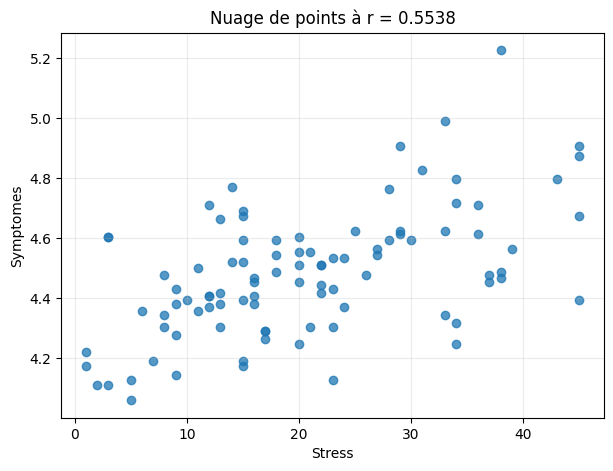

Coefficient de corrélation r = 0.553757
Valeur-p du test de corrélation = 0.0000000059


In [16]:
r, p_corr = stats.pearsonr(df['Stress'], df['Symptomes'])
plt.figure(figsize=(7, 5))
plt.scatter(df['Stress'], df['Symptomes'], alpha=0.75)
plt.xlabel('Stress')
plt.ylabel('Symptomes')
plt.title(f'Nuage de points à r = {r:.4f}')
plt.grid(alpha=0.25)
plt.show()
print(f'Coefficient de corrélation r = {r:.6f}')
print(f'Valeur-p du test de corrélation = {p_corr:.10f}')


**Résultat :**

$$
r=0{,}5538,\qquad p\approx5{,}86\times10^{-9}.
$$



**Interprétation.** On obtient $r\approx0{,}554$. La corrélation linéaire est donc **positive et modérée** : les étudiants ayant davantage de stress tendent à avoir davantage de symptômes, mais les points ne sont pas parfaitement alignés. La valeur-p très petite indique que cette corrélation est statistiquement différente de zéro dans cet échantillon. Corrélation ne signifie toutefois pas causalité.

## 10. Droite de régression et prédiction

La droite de régression de $Y$= Symptomes en fonction de $X$= Stress, obtenue par la méthode des moindres carrés, est déterminée à partir des moyennes, des écarts-types et du coefficient de corrélation de Pearson :

$$
\widehat{y}=a+bx,
$$

où

$$
b=r\frac{s_y}{s_x},
\qquad
a=\bar{y}-b\bar{x}.
$$




In [17]:
x = df['Stress']
sx = x.std(ddof=1)
sy = y.std(ddof=1)
b = r * sy / sx
a = moyenne_y - b * x.mean()
x_nouveau = 47
prediction = a + b * x_nouveau
r2 = r**2
print(f'x_bar = {x.mean():.6f}, y_bar = {moyenne_y:.6f}')
print(f's_x = {sx:.6f}, s_y = {sy:.6f}')
print(f'r = {r:.6f}')
print(f'pente b = {b:.6f}')
print(f"ordonnée à l'origine a = {a:.6f}")
print(f'droite : y_chapeau = {a:.6f} + {b:.6f} x')
print(f'r^2 = {r2:.6f} = {100*r2:.2f} %')
print(f'prédiction pour Stress = 47 : {prediction:.6f}')
observations_47 = df.loc[df['Stress'].eq(47), ['Stress', 'Symptomes']]
print('Observations avec Stress exactement égal à 47 :')
display(observations_47)
print('Observations les plus proches de 47 :')
display(df.assign(distance=(df['Stress']-47).abs()).sort_values('distance').head())


x_bar = 20.694737, y_bar = 4.481809
s_x = 11.412082, s_y = 0.211537
r = 0.553757
pente b = 0.010265
ordonnée à l'origine a = 4.269386
droite : y_chapeau = 4.269386 + 0.010265 x
r^2 = 0.306647 = 30.66 %
prédiction pour Stress = 47 : 4.751821
Observations avec Stress exactement égal à 47 :


,Stress,Symptomes


Observations les plus proches de 47 :


,Stress,Symptomes,distance
31,45,4.9053,2
27,45,4.8752,2
29,45,4.6728,2
60,45,4.3944,2
44,43,4.7958,4


Avec $r=0{,}5538$, $s_y=0{,}2115$, $s_x=11{,}4121$, $\bar{x}=20{,}6947$ et $\bar{y}=4{,}4818$, on obtient :

$$
b=0{,}5538\left(\frac{0{,}2115}{11{,}4121}\right)
\approx 0{,}010265,
$$

$$
a=4{,}4818-0{,}010265(20{,}6947)
\approx 4{,}2694.
$$

Ainsi, l'équation de la droite de régression est :

$$
\boxed{\widehat{y}=4{,}2694+0{,}010265x}.
$$

Pour un score de stress égal à \(47\) :

$$
\widehat{y}(47)
=4{,}2694+0{,}010265(47)
\approx 4{,}7518.
$$

Le coefficient de détermination est :

$$
R^2=r^2=(0{,}5538)^2\approx0{,}3066.
$$

**Interprétation finale.** 

Il n'y a pas d'observation avec `Stress` exactement égal à 47 dans le fichier; il est donc impossible de comparer cette prédiction à un score observé à $X=47$. Les observations les plus proches ont `Stress=45`, mais elles ne constituent pas une observation à 47 et ne doivent pas être présentées comme telle. Le coefficient de détermination est $r^2\approx0{,}3066$ : environ 30,66 % de la variabilité linéaire du score de symptômes est expliquée par le stress dans cet échantillon.

## Synthèse des résultats numériques

| Élément | Résultat approximatif |
|---|---:|
| $n$ | 95 |
| Moyenne Stress | 20,6947 |
| Écart-type Stress | 11,4121 |
| Moyenne Symptomes | 4,4818 |
| Écart-type Symptomes | 0,2115 |
| IC 95 % de $\mu_Y$ | $[4,4387;4,5249]$ |
| Taille pour $ME\le0,025$ | 276 |
| Test $H_1:\mu<4,5$ | non-rejet de $H_0$ |
| Khi-carré 2×2 | $\chi^2=9,8919$, $p=0,00166$ |
| Corrélation | $r=0,5538$ |
| Régression | $\hat y=4,2694+0,01026x$ |
| Prédiction pour $x=47$ | 4,7518 |

Avant de remettre le devoir, vérifier la mise en page, ajouter les noms des membres de l'équipe, indiquer les contributions et exporter le notebook ou le rapport en PDF selon les directives.